Este notebook tem como objetivo explorar os datasets sobre a temperatura global anual, o forçante radiativo efetivo global e o indice oceanico relativo do El Niño, a fim de descobrir possíveis correlações entre os dados coletados. 

O forçante radiativo é a mudança no balanço de energia da Terra causada por algum fator externo, medida em watts por metro quadrado (W/m²). Um forçante de +1 W/m² significa que, em média, cada metro quadrado do topo da atmosfera passa a receber 1 watt a mais do que emite.

Referências dos datasets:

Global Temperature - Earth Indicator: https://science.nasa.gov/earth/explore/earth-indicators/global-temperature/

forcing-timeseries: https://github.com/ClimateIndicator/forcing-timeseries



### Leitura dos dados

In [124]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ERF_PATH = '../tratamento/dados_tratados/dados_analise_climatica/ERF_best_aggregates.csv'
TEMP_PATH = '../tratamento/dados_tratados/dados_analise_climatica/temperatura_global.csv'
RONI_PATH = '../tratamento/dados_tratados/dados_el_nino/dados_El_nino_RONI.csv'
ONI_PATH = '../tratamento/dados_tratados/dados_el_nino/dados_El_nino_ONI.csv'

erf_df = pd.read_csv(ERF_PATH, index_col=[0])
temp_df = pd.read_csv(TEMP_PATH)
roni_df = pd.read_csv(RONI_PATH)
oni_df = pd.read_csv(ONI_PATH)

### Análise de Distribuição 

#### dados de anomalia da temperatura no pacífico equatorial central-leste.

agrupamos os datasets ONI e RONI em eventos únicos de ocorrência do el nino, onde cada evento representa uma seqência de semestres na fase de El-Niño, aplicamos uma função max para exibir o pico do valor da anomalia de temperatura de cada evento.

In [125]:

df = roni_df.copy()
is_el = df['FASE'].eq('El Niño')
df['evento'] = (is_el != is_el.shift()).cumsum()

df = (
    df[is_el]
    .groupby('evento')
    .agg(anom_max_evento=('ANOM', 'max'),
         YR=('YR', 'max'),
         n_trimestres=('ANOM', 'size'))
)

df = df[df['n_trimestres'] >= 5].reset_index(drop=True)   # filtra ANTES de numerar
df['evento'] = df.index + 1

roni_anom_max_evento = df
df.head(50)

,anom_max_evento,YR,n_trimestres,evento
0,1.04,1952,10,1
1,0.94,1954,13,2
2,1.89,1958,16,3
3,1.11,1964,8,4
4,1.99,1966,12,5
5,1.07,1969,6,6
6,1.97,1973,12,7
7,1.08,1977,8,8
8,1.10,1978,6,9
9,2.40,1983,13,10


In [126]:

df = oni_df.copy()
is_el = df['FASE'].eq('El Niño')
df['evento'] = (is_el != is_el.shift()).cumsum()

df = (
    df[is_el]
    .groupby('evento')
    .agg(anom_max_evento=('ANOM', 'max'),
         YR=('YR', 'max'),
         n_trimestres=('ANOM', 'size'))
)

df = df[df['n_trimestres'] >= 5].reset_index(drop=True)   # filtra ANTES de numerar
df['evento'] = df.index + 1

oni_anom_max_evento = df
df.head(50)

,anom_max_evento,YR,n_trimestres,evento
0,1.03,1952,8,1
1,0.78,1953,9,2
2,1.69,1958,14,3
3,1.19,1964,8,4
4,1.82,1966,10,5
5,0.98,1969,8,6
6,1.84,1973,10,7
7,0.84,1977,6,8
8,0.84,1978,5,9
9,2.14,1983,14,10


plotamos ambos os dados 

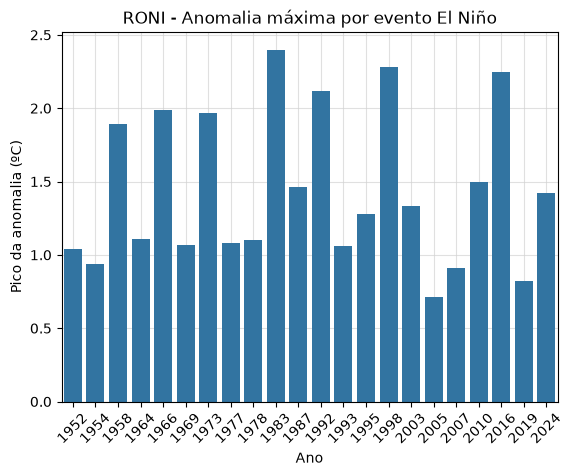

In [127]:
import seaborn as sns
ax = sns.barplot(data=roni_anom_max_evento, x= 'YR', y='anom_max_evento', )
ax.set_ylim(bottom=0)
ax.set_title('RONI - Anomalia máxima por evento El Niño')
ax.tick_params(axis= 'x',rotation=45)
ax.set_xlabel('Ano')
ax.set_ylabel('Pico da anomalia (ºC)')

ax.grid(True, color='lightgray', linewidth=0.8, alpha=0.7)
ax.set_axisbelow(True)  # deixa a grade atrás da linha
plt.show()

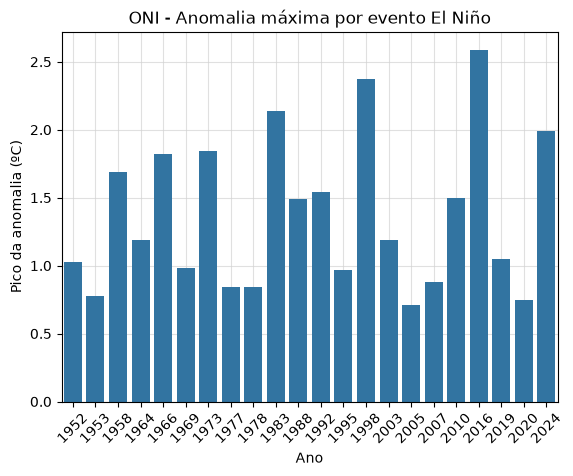

In [128]:
ax = sns.barplot(data=oni_anom_max_evento, x= 'YR', y='anom_max_evento', )
ax.set_ylim(bottom=0)
ax.set_title('ONI - Anomalia máxima por evento El Niño')
ax.tick_params(axis= 'x',rotation=45)
ax.set_xlabel('Ano')
ax.set_ylabel('Pico da anomalia (ºC)')

ax.grid(True, color='lightgray', linewidth=0.8, alpha=0.7)
ax.set_axisbelow(True)  # deixa a grade atrás da linha
plt.show()

#### Dados do forçante radiativo global

O forçamento radiativo efetivo (ERF, em W/m²) mede a variação no balanço de energia da Terra causada por um agente climático, já considerando os ajustes rápidos da atmosfera. Valores positivos indicam aquecimento e valores negativos indicam resfriamento. Os dados usados aqui correspondem à estimativa central, o percentil 5 e o percentil 95 da série de ERF, com valores anuais de 1750 a 2025 e uma coluna para cada agente.

O gráfico abaixo mostra, para o período de 1950 a 2025, as contribuições de dois grupos de agentes em áreas empilhadas:

- **Gases de efeito estufa de longa vida :** CO₂, CH₄, N₂O e gases halogenados. A altura total da pilha é o forçamento combinado desses gases.
- **Aerossóis :** interação com a radiação e interação com as nuvens. Eles refletem a luz solar e tornam as nuvens mais brilhantes, o que causa um efeito de resfriamento que compensa parte do aquecimento dos gases.

O gráfico mostra que o forçamento positivo cresce de forma contínua ao longo do período, com o CO₂ como o maior componente. O resfriamento dos aerossóis é menor em magnitude e tem menos incerteza associada ao seu padrão de crescimento, mas ainda é relevante. O forçamento total também inclui outros agentes (ozônio, uso do solo, solar, vulcânico etc.) que não aparecem nesta figura.

In [129]:
def plot_erf_stack(
    df,
    gases=('CO2', 'CH4', 'N2O', 'halogen'),
    aerossois=('aerosol-radiation_interactions', 'aerosol-cloud_interactions'),
    labels_gases=('CO₂', 'CH₄', 'N₂O', 'Halogenados'),
    labels_aerossois=('Aerossóis (interação com radiação)', 'Aerossóis (interação com nuvens)'),
    ano_inicio=1950,
    ano_fim=2026,
    passo_xticks=5,
    figsize=(10, 5),
    ax=None,
):

    fig, ax = plt.subplots(figsize=(10, 5))

    gases = ['CO2', 'CH4', 'N2O', 'halogen']
    aerossois = ['aerosol-radiation_interactions', 'aerosol-cloud_interactions']

    cores_gases = sns.color_palette('deep', n_colors=len(gases))
    cores_aer = sns.color_palette('pastel', n_colors=len(aerossois))

    ax.stackplot(
        df.index, [df[g] for g in gases], 
        labels=labels_gases,
        colors=cores_gases,
        alpha=0.85,
    )

    ax.stackplot(
        df.index,
        [df[a] for a in aerossois],
        labels=labels_aerossois,
        colors=cores_aer,
        alpha=0.85,
    )

    ax.set_xticks(range(ano_inicio,ano_fim, passo_xticks))
    ax.set_ylabel('ERF (W/m²)')
    ax.set_xlabel('Ano')
    ax.set_xlim(left=1950, right=2026)
    ax.tick_params(axis= 'x',rotation=45)
    ax.legend(loc='upper left', title='Gases de longa vida')

    ax.grid(True, color='lightgray', linewidth=0.8, alpha=0.7)
    ax.set_axisbelow(True) 

    return ax


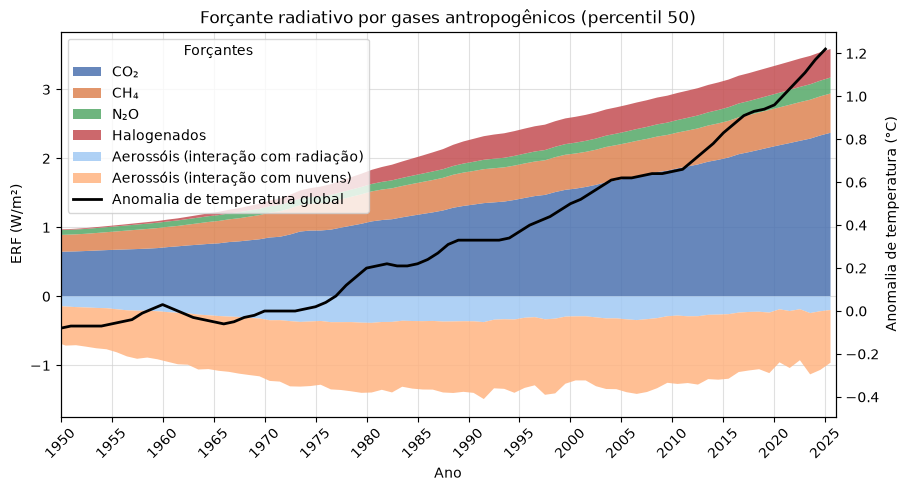

In [130]:
ax = plot_erf_stack(erf_df)
ax.set_title('Forçante radiativo por gases antropogênicos (percentil 50)')
ax2 = ax.twinx()

ax2.plot(temp_df['Year'], temp_df['Lowess(5)'],
         color='black', linewidth=2, label='Anomalia de temperatura global')
ax2.set_ylabel('Anomalia de temperatura (°C)')
ax2.set_xlim(1950, 2026)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', title='Forçantes')

plt.show()

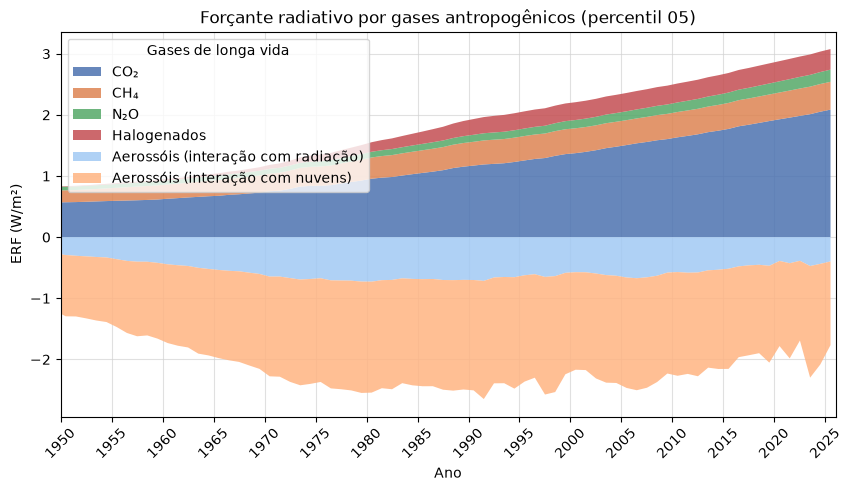

In [131]:
ERF_P05_PATH = '../tratamento/dados_tratados/dados_analise_climatica/ERF_p05_aggregates.csv'
df = pd.read_csv(ERF_P05_PATH, index_col=0)
ax = plot_erf_stack(df)
ax.set_title('Forçante radiativo por gases antropogênicos (percentil 05)')

plt.show()

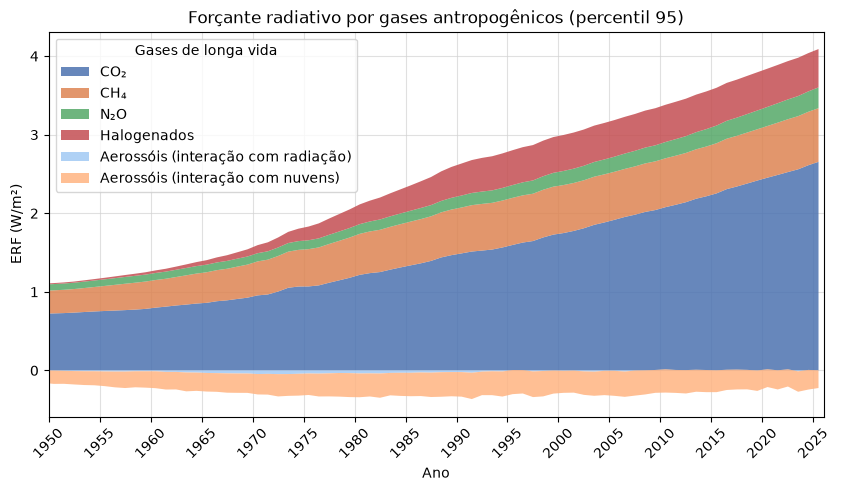

In [132]:
ERF_P05_PATH = '../tratamento/dados_tratados/dados_analise_climatica/ERF_p95_aggregates.csv'
df = pd.read_csv(ERF_P05_PATH, index_col=0)
ax = plot_erf_stack(df)
ax.set_title('Forçante radiativo por gases antropogênicos (percentil 95)')

plt.show()